# Initialisation
Code below is for preppring tools for use

---

In [131]:
# import plotting tools
# plotnine is the python clone of ggplot2 from R
# this should be used over plt where possible

import pandas as pd
import matplotlib as plt
from plotnine import *
import numpy as np
import re

In [132]:
from collections import *
from skimage import *
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [133]:
from transformers import AutoTokenizer, pipeline, AutoModel
import torch
import re
from thefuzz import process

In [134]:
def clean_column_names(df):
    """Strips [Note X] tags and trailing whitespace from dataframe column names."""
    new_cols = {}
    for col in df.columns:
        # Removes patterns like ' [Note 6]', '[Note 7]', etc.
        cleaned = re.sub(r'\s*\[Note\s*\d+\]', '', str(col)).strip()
        new_cols[col] = cleaned
    return df.rename(columns=new_cols)

# Cross sectional data analysis -> 2025
The code below is for the testing of basic premise and ideas, such as probing raw statistics and the like. This may also be used for getting familuar with certain tools and datasets.

In [135]:
df = pd.read_csv('att_sch_stats/att_sch.csv')

attainment_2025 = df[df['DateCode'].astype(str).str.contains("2024-25", na=False)]
above_5_2025 = attainment_2025[
    (
        attainment_2025['Number Of Awards'].astype(str).str.contains("5", na=False)
    ) & (
        attainment_2025['SCQF Level'].astype(str).str.contains("6", na=False)
    )
]
att_list = above_5_2025[["GeographyName", "Value"]]
att_list = att_list.sort_values(by="GeographyName")
att_list = att_list[att_list.GeographyName != "National"]

supressors = ["*", "#"]

supressed_schools = att_list[
    att_list["Value"].astype(str).isin(supressors)
].sort_values(by="GeographyName")

att_list = att_list[
    ~att_list["Value"].astype(str).isin(supressors)
].copy()

att_list

,GeographyName,Value
155091,Aberdeen Grammar School,72
155511,Aboyne Academy,46
171891,Airdrie Academy,35
154111,Alford Academy,41
169511,All Saints Secondary School,38
...,...,...
171261,Whitehill Secondary School,22
151241,Wick High School,18
174131,Williamwood High School,82
174061,Woodfarm High School,74


In [136]:
primary_ys = ["P1", "P2", "P3", "P4", "P5", "P6", "P7"]

sch_sum_2025 = pd.read_excel('sch_sum_stats/sch_sum_2025.xlsx', sheet_name=2, header=1)
hs_sum_2025 = sch_sum_2025[sch_sum_2025["School Type"].astype(str).str.contains("Secondary")]
hs_sum_2025 = hs_sum_2025.drop(columns=primary_ys).drop(columns="Special school pupils")
hs_sum_2025 = hs_sum_2025.sort_values(by="School Name")
# the below lines needs manually cleaned and removed it is outdated
hs_sum_2025 = hs_sum_2025[~hs_sum_2025["School Name"].astype(str).isin(["Braeview Academy", "Craigie High School", "Glasgow Gaelic School", "St Joseph's Academy", "The Community School of Auchterarder"])]

supressed_names = supressed_schools["GeographyName"].to_list()
pattern = '|'.join(re.escape(name) for name in supressed_names)
hs_sum_2025 = hs_sum_2025[~hs_sum_2025["School Name"].astype(str).str.contains(pattern, case=False)].copy()

hs_sum_2025 = clean_column_names(hs_sum_2025)

# hs_sum_2025 = hs_sum_2025[~hs_sum_2025["School Name"].astype(str).isin(supressed_schools["GeographyName"])].copy()
# hs_sum_2025 = hs_sum_2025[hs_sum_2025["School Name"].astype(str).isin(att_list["GeographyName"])]
att_list = att_list[att_list["GeographyName"].astype(str).isin(hs_sum_2025["School Name"].astype(str))].copy()
hs_sum_2025 = hs_sum_2025[hs_sum_2025["School Name"].astype(str).isin(att_list["GeographyName"].astype(str))].copy()

In [137]:
target = "Value"

simd_columns = [
    "SIMD Quintile 1",
    "SIMD Quintile 2",
    "SIMD Quintile 3",
    "SIMD Quintile 4",
    "SIMD Quintile 5"
]

numeric_columns = simd_columns + ["Pupil roll"]

for column in numeric_columns:
    hs_sum_2025[column] = pd.to_numeric(
        hs_sum_2025[column]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.strip(),
        errors="coerce"
    )

for column in simd_columns:
    hs_sum_2025[f"{column} proportion"] = (
        hs_sum_2025[column] / hs_sum_2025["Pupil roll"]
    )

simd_features = [
    f"{column} proportion"
    for column in simd_columns
]


In [138]:
URC = ["Urban", "Small town", "Rural"]

def find_midpoint(val):
    if pd.isna(val):
        return np.nan

    val = str(val).strip().replace("%","")
    lower, upper = val.split("-")
    return (float(lower) + float(upper)) / 200

for column in URC:
    hs_sum_2025[f"{column} proportion"] = (
        hs_sum_2025[column].apply(find_midpoint)
    )

URF = [
    f"{column} proportion"
    for column in URC
]

In [139]:
denomination = "Denomination of school"

hs_sum_2025["Denomination Encoded"] = (
    hs_sum_2025[denomination]
    .map({
        "Non-denominational school" : 0,
        "Roman Catholic School" : 1
    })
)

In [140]:
features = [
    "Average class size",
    "Pupil roll",
    "Pupil Teacher Ratio",
    "Pupils with an Additional Support Need recorded",
    "Denomination Encoded",
    *simd_features,
    *URF,
]

In [141]:
data = hs_sum_2025.merge(
    att_list[["GeographyName", "Value"]],
    left_on="School Name",
    right_on="GeographyName",
    how="inner",
    validate="one_to_one"
)

x = data[features]
y = pd.to_numeric(data["Value"], errors="coerce")

valid = y.notna()
x = x.loc[valid].copy()
y = y.loc[valid].copy()
numeric_features = features

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features)
])

In [142]:
X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42
)

In [143]:
model = Pipeline([
    ("Preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=500,
        random_state=42,
    ))
])
model.fit(X_train, y_train)
predictions = model.predict(X_test)
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 8.285910447761195
RMSE: 10.385160118484798
R²: 0.5064382172772146


In [144]:
# import matplotlib.pyplot as plt

# # 1. Calculate average Pupil Teacher Ratio per council
# avg_ptr = db.groupby("Local Authority")["Pupil Teacher Ratio"].mean().reset_index()

# # 2. Create figure and axes object properly
# fig, ax = plt.subplots(figsize=(10, 6))

# # 3. Plot a horizontal bar chart
# ax.barh(avg_ptr["Local Authority"], avg_ptr["Pupil Teacher Ratio"], color="skyblue")

# ax.set_xlabel("Average Pupil Teacher Ratio")
# ax.set_ylabel("Local Authority")
# ax.set_title("Average Pupil Teacher Ratio by Council")

# plt.tight_layout()
# plt.show()
print(hs_sum_2025[numeric_columns].isna().sum())

SIMD Quintile 1    32
SIMD Quintile 2    23
SIMD Quintile 3     7
SIMD Quintile 4    19
SIMD Quintile 5    34
Pupil roll          0
dtype: int64


---

# CS 2024
starting 2024
Code may be duplicated before possible functions are identified

In [145]:
df = pd.read_csv('att_sch_stats/att_sch.csv')

attainment_2024 = df[df['DateCode'].astype(str).str.contains("2023-24", na=False)]
above_5_2024 = attainment_2024[
    (
        attainment_2024['Number Of Awards'].astype(str).str.contains("5", na=False)
    ) & (
        attainment_2024['SCQF Level'].astype(str).str.contains("6", na=False)
    )
]
att_list_24 = above_5_2024[["GeographyName", "Value"]]
att_list_24 = att_list_24.sort_values(by="GeographyName")
att_list_24 = att_list_24[att_list_24.GeographyName != "National"]

supressors = ["*", "#"]

supressed_schools = att_list_24[
    att_list_24["Value"].astype(str).isin(supressors)
].sort_values(by="GeographyName")

att_list_24 = att_list_24[
    ~att_list_24["Value"].astype(str).isin(supressors)
].copy()

att_list_24= att_list_24.dropna()

In [146]:
primary_ys = ["P1", "P2", "P3", "P4", "P5", "P6", "P7"]

sch_sum_2024 = pd.read_excel('sch_sum_stats/sch_sum_2024.xlsx', sheet_name=2, header=1)
hs_sum_2024 = sch_sum_2024[sch_sum_2024["School Type"].astype(str).str.contains("Secondary")]
hs_sum_2024 = hs_sum_2024.drop(columns=primary_ys).drop(columns="Special school pupils")
hs_sum_2024 = hs_sum_2024.sort_values(by="School Name")
# hs_sum_2024 = hs_sum_2024[~hs_sum_2024["School Name"].astype(str).isin(["Braeview Academy", "Craigie High School", "Glasgow Gaelic School", "St Joseph's Academy", "The Community School of Auchterarder"])]

supressed_names = supressed_schools["GeographyName"].to_list()
pattern = '|'.join(re.escape(name) for name in supressed_names)
hs_sum_2024 = hs_sum_2024[~hs_sum_2024["School Name"].astype(str).str.contains(pattern, case=False)].copy()

hs_sum_2024 = clean_column_names(hs_sum_2024)

# hs_sum_2025 = hs_sum_2025[~hs_sum_2025["School Name"].astype(str).isin(supressed_schools["GeographyName"])].copy()
# hs_sum_2025 = hs_sum_2025[hs_sum_2025["School Name"].astype(str).isin(att_list["GeographyName"])]
att_list_24 = att_list_24[att_list_24["GeographyName"].astype(str).isin(hs_sum_2024["School Name"].astype(str))].copy()
hs_sum_2024 = hs_sum_2024[hs_sum_2024["School Name"].astype(str).isin(att_list_24["GeographyName"].astype(str))].copy()

hs_sum_2024

,Local Authority,SeedCode,School Name,School Type,Teachers (Full Time Equivalent),Pupil roll,Pupil Teacher Ratio,Average class size,Female,Male,...,Small town,Rural,Urban/rural classification not available,Attendance rate (%),Authorised absence rate (%),Unauthorised absence rate (%),Absence due to temporary exclusion rate (%),School's 6-fold urban/rural classification,School's 8-fold urban/rural classification,Denomination of school
6,Aberdeen City,5244439,Aberdeen Grammar School,Secondary,101.2,1310,12.9,0,628,682,...,0-10%,0-10%,0-10%,92.66,5.81,1.5,0.03,Large urban areas,Large urban areas,Non-denominational
19,Aberdeenshire,5257530,Aboyne Academy,Secondary,59.6,659,11.1,0,315,344,...,0-10%,90-100%,0-10%,90.94,6.64,2.41,C,Remote rural areas,Remote rural areas,Non-denominational
27,North Lanarkshire,8505438,Airdrie Academy,Secondary,74.7,1044,14.0,0,533,511,...,0-10%,20-30%,0-10%,83.47,6.18,10.32,0.03,Other urban areas,Other urban areas,Non-denominational
39,Aberdeenshire,5230934,Alford Academy,Secondary,60.6,687,11.3,0,316,371,...,0-10%,90-100%,0-10%,89.83,6.64,3.46,0.06,Remote rural areas,Remote rural areas,Non-denominational
43,Glasgow City,8431930,All Saints Secondary School,Secondary,67.2,911,13.6,0,474,437,...,0-10%,0-10%,0-10%,86.93,7.06,5.99,0.02,Large urban areas,Large urban areas,Roman Catholic
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2402,Glasgow City,8439532,Whitehill Secondary School,Secondary,61.4,618,10.1,0,287,331,...,0-10%,0-10%,0-10%,83.37,4.49,12.13,C,Large urban areas,Large urban areas,Non-denominational
2411,Highland,5102138,Wick High School,Secondary,56.5,736,13.0,0,370,366,...,50-60%,40-50%,0-10%,85.7,8.67,5.62,C,Remote small towns,Very Remote Small Towns,Non-denominational
2415,East Renfrewshire,8602034,Williamwood High School,Secondary,140.8,1678,11.9,0,843,835,...,0-10%,0-10%,0-10%,91.95,5.39,2.65,0.01,Large urban areas,Large urban areas,Non-denominational
2428,East Renfrewshire,8601836,Woodfarm High School,Secondary,74.8,701,9.4,0,333,368,...,0-10%,0-10%,0-10%,91.68,6.19,2.11,0.01,Large urban areas,Large urban areas,Non-denominational


In [147]:
# School name columns
att_schools = att_list_24["GeographyName"]
hs_schools = hs_sum_2024["School Name"]

# Schools in att_list but not hs_sum_2024
missing_from_hs = sorted(set(att_schools) - set(hs_schools))

# Schools in hs_sum_2024 but not att_list
missing_from_att = sorted(set(hs_schools) - set(att_schools))

differences = pd.DataFrame({
    "School Name": (
        [*missing_from_hs, *missing_from_att]
    ),
    "Missing From": (
        ["hs_sum_2024"] * len(missing_from_hs)
        + ["att_list"] * len(missing_from_att)
    )
})

display(differences)

,School Name,Missing From


In [148]:
target = "Value"

simd_columns = [
    "SIMD Quintile 1",
    "SIMD Quintile 2",
    "SIMD Quintile 3",
    "SIMD Quintile 4",
    "SIMD Quintile 5"
]

numeric_columns = simd_columns + ["Pupil roll"]

for column in numeric_columns:
    hs_sum_2024[column] = pd.to_numeric(
        hs_sum_2024[column]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.strip(),
        errors="coerce"
    )

for column in simd_columns:
    hs_sum_2024[f"{column} proportion"] = (
        hs_sum_2024[column] / hs_sum_2024["Pupil roll"]
    )

simd_features = [
    f"{column} proportion"
    for column in simd_columns
]


In [149]:
URC = ["Urban", "Small town", "Rural"]

for column in URC:
    hs_sum_2024[f"{column} proportion"] = (
        hs_sum_2024[column].apply(find_midpoint)
    )

URF = [
    f"{column} proportion"
    for column in URC
]

In [150]:
denomination = "Denomination of school"

hs_sum_2024["Denomination Encoded"] = (
    hs_sum_2024[denomination]
    .map({
        "Non-denominational" : 0,
        "Roman Catholic" : 1
    })
)

In [151]:
features = [
    "Average class size",
    "Pupil roll",
    "Pupil Teacher Ratio",
    "Pupils with an Additional Support Need recorded",
    "Denomination Encoded",
    *simd_features,
    *URF,
]

In [152]:
data = hs_sum_2024.merge(
    att_list_24[["GeographyName", "Value"]],
    left_on="School Name",
    right_on="GeographyName",
    how="inner",
    validate="one_to_one"
)

x = data[features]
y = pd.to_numeric(data["Value"], errors="coerce")

valid = y.notna()
x = x.loc[valid].copy()
y = y.loc[valid].copy()
numeric_features = features

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features)
])

In [153]:
X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42
)

In [154]:
model = Pipeline([
    ("Preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=500,
        random_state=42,
    ))
])
model.fit(X_train, y_train)
predictions = model.predict(X_test)
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 7.946735294117648
RMSE: 9.932631944904692
R²: 0.4814145685661767


---
# CS 2023
as mentioned above, code repition will be present in the mean time until clean up and organisation is more suitable

In [155]:
df = pd.read_csv('att_sch_stats/att_sch.csv')

attainment_2023 = df[df['DateCode'].astype(str).str.contains("2022-23", na=False)]
above_5_2023 = attainment_2023[
    (
        attainment_2023['Number Of Awards'].astype(str).str.contains("5", na=False)
    ) & (
        attainment_2023['SCQF Level'].astype(str).str.contains("6", na=False)
    )
]
att_list_23 = above_5_2023[["GeographyName", "Value"]]
att_list_23 = att_list_23.sort_values(by="GeographyName")
att_list_23 = att_list_23[att_list_23.GeographyName != "National"]

supressors = ["*", "#"]

supressed_schools = att_list_23[
    att_list_23["Value"].astype(str).isin(supressors)
].sort_values(by="GeographyName")

att_list_23 = att_list_23[
    ~att_list_23["Value"].astype(str).isin(supressors)
].copy()

att_list_23 = att_list_23.dropna()

In [156]:
primary_ys = ["P1", "P2", "P3", "P4", "P5", "P6", "P7"]

sch_sum_2023 = pd.read_excel('sch_sum_stats/sch_sum_2023.xlsx', sheet_name=2, header=1)
hs_sum_2023 = sch_sum_2023[sch_sum_2023["School Type"].astype(str).str.contains("Secondary")]
hs_sum_2023 = hs_sum_2023.drop(columns=primary_ys).drop(columns="Special school pupils")
hs_sum_2023 = hs_sum_2023.sort_values(by="School Name")
# hs_sum_2024 = hs_sum_2024[~hs_sum_2024["School Name"].astype(str).isin(["Braeview Academy", "Craigie High School", "Glasgow Gaelic School", "St Joseph's Academy", "The Community School of Auchterarder"])]

supressed_names = supressed_schools["GeographyName"].to_list()
pattern = '|'.join(re.escape(name) for name in supressed_names)
hs_sum_2023 = hs_sum_2023[~hs_sum_2023["School Name"].astype(str).str.contains(pattern, case=False)].copy()
hs_sum_2023 = clean_column_names(hs_sum_2023)

# hs_sum_2025 = hs_sum_2025[~hs_sum_2025["School Name"].astype(str).isin(supressed_schools["GeographyName"])].copy()
# hs_sum_2025 = hs_sum_2025[hs_sum_2025["School Name"].astype(str).isin(att_list["GeographyName"])]
att_list_23 = att_list_23[att_list_23["GeographyName"].astype(str).isin(hs_sum_2023["School Name"].astype(str))].copy()
hs_sum_2023 = hs_sum_2023[hs_sum_2023["School Name"].astype(str).isin(att_list_23["GeographyName"].astype(str))].copy()

hs_sum_2023

,Local Authority,SeedCode,School Name,School Type,Teachers (Full Time Equivalent),Pupil roll,Pupil Teacher Ratio,Average class size,Female,Male,...,Small town,Rural,Urban/rural classification not available,Attendance rate (%),Authorised absence rate (%),Unauthorised absence rate (%),Absence due to temporary exclusion rate (%),School's 6-fold urban/rural classification,School's 8-fold urban/rural classification,Denomination of school
6,Aberdeen City,5244439,Aberdeen Grammar School,Secondary,107.4,1205,11.2,0,567,638,...,0-10%,0-10%,0-10%,92.04,5.88,2.05,0.03,Large urban areas,Large urban areas,Non-denominational
18,Aberdeenshire,5257530,Aboyne Academy,Secondary,60.6,669,11.0,0,320,349,...,0-10%,90-100%,0-10%,92.26,5.67,c,c,Remote rural areas,Remote rural areas,Non-denominational
26,North Lanarkshire,8505438,Airdrie Academy,Secondary,73.9,1032,14.0,0,533,499,...,0-10%,20-30%,0-10%,82.98,5.84,11.14,0.04,Other urban areas,Other urban areas,Non-denominational
38,Aberdeenshire,5230934,Alford Academy,Secondary,59.0,733,12.4,0,344,389,...,0-10%,90-100%,0-10%,89.59,6.42,3.92,0.07,Remote rural areas,Remote rural areas,Non-denominational
42,Glasgow City,8431930,All Saints Secondary School,Secondary,67.6,905,13.4,0,461,444,...,0-10%,0-10%,0-10%,89.22,5.82,4.94,0.02,Large urban areas,Large urban areas,Roman Catholic
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2408,West Lothian,5510430,Whitburn Academy,Secondary,64.1,851,13.3,0,419,432,...,30-40%,0-10%,0-10%,82.32,13.33,4.34,0.02,Other urban areas,Other urban areas,Non-denominational
2413,Glasgow City,8439532,Whitehill Secondary School,Secondary,56.4,604,10.7,0,264,340,...,0-10%,0-10%,0-10%,87.07,4.82,c,c,Large urban areas,Large urban areas,Non-denominational
2426,East Renfrewshire,8602034,Williamwood High School,Secondary,143.8,1668,11.6,0,849,819,...,0-10%,0-10%,0-10%,92.34,5.01,2.64,0.01,Large urban areas,Large urban areas,Non-denominational
2439,East Renfrewshire,8601836,Woodfarm High School,Secondary,70.8,693,9.8,0,339,354,...,0-10%,0-10%,0-10%,91.79,6.46,c,c,Large urban areas,Large urban areas,Non-denominational


In [157]:
# School name columns
att_schools = att_list_23["GeographyName"]
hs_schools = hs_sum_2023["School Name"]

# Schools in att_list but not hs_sum_2023
missing_from_hs = sorted(set(att_schools) - set(hs_schools))

# Schools in hs_sum_2023 but not att_list
missing_from_att = sorted(set(hs_schools) - set(att_schools))

differences = pd.DataFrame({
    "School Name": (
        [*missing_from_hs, *missing_from_att]
    ),
    "Missing From": (
        ["hs_sum_2023"] * len(missing_from_hs)
        + ["att_list"] * len(missing_from_att)
    )
})

display(differences)

,School Name,Missing From


In [158]:
target = "Value"

simd_columns = [
    "SIMD Quintile 1",
    "SIMD Quintile 2",
    "SIMD Quintile 3",
    "SIMD Quintile 4",
    "SIMD Quintile 5"
]

numeric_columns = simd_columns + ["Pupil roll"]

for column in numeric_columns:
    hs_sum_2023[column] = pd.to_numeric(
        hs_sum_2023[column]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.strip(),
        errors="coerce"
    )

for column in simd_columns:
    hs_sum_2023[f"{column} proportion"] = (
        hs_sum_2023[column] / hs_sum_2023["Pupil roll"]
    )

simd_features = [
    f"{column} proportion"
    for column in simd_columns
]


In [159]:
denomination = "Denomination of school"

hs_sum_2023["Denomination Encoded"] = (
    hs_sum_2023[denomination]
    .map({
        "Non-denominational" : 0,
        "Roman Catholic" : 1
    })
)

In [160]:
URC = ["Urban", "Small town", "Rural"]

for column in URC:
    hs_sum_2023[f"{column} proportion"] = (
        hs_sum_2023[column].apply(find_midpoint)
    )

URF = [
    f"{column} proportion"
    for column in URC
]

In [161]:
features = [
    "Average class size",
    "Pupil roll",
    "Pupil Teacher Ratio",
    "Pupils with an Additional Support Need recorded",
    "Denomination Encoded",
    *simd_features,
    *URF,
]

In [162]:
data = hs_sum_2023.merge(
    att_list_23[["GeographyName", "Value"]],
    left_on="School Name",
    right_on="GeographyName",
    how="inner",
    validate="one_to_one"
)

x = data[features]
y = pd.to_numeric(data["Value"], errors="coerce")

valid = y.notna()
x = x.loc[valid].copy()
y = y.loc[valid].copy()
numeric_features = features

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features)
])

In [163]:
X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42
)

In [164]:
model = Pipeline([
    ("Preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=500,
        random_state=42,
    ))
])
model.fit(X_train, y_train)
predictions = model.predict(X_test)
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 9.847373134328357
RMSE: 11.647260752845543
R²: 0.42337892083734185


---
# CS 2022
as before expect code repition until clean up

In [165]:
df = pd.read_csv('att_sch_stats/att_sch.csv')

attainment_2022 = df[df['DateCode'].astype(str).str.contains("2021-22", na=False)]
above_5_2022 = attainment_2022[
    (
        attainment_2022['Number Of Awards'].astype(str).str.contains("5", na=False)
    ) & (
        attainment_2022['SCQF Level'].astype(str).str.contains("6", na=False)
    )
]
att_list_22 = above_5_2022[["GeographyName", "Value"]]
att_list_22 = att_list_22.sort_values(by="GeographyName")
att_list_22 = att_list_22[att_list_22.GeographyName != "National"]

supressors = ["*", "#"]

supressed_schools = att_list_22[
    att_list_22["Value"].astype(str).isin(supressors)
].sort_values(by="GeographyName")

att_list_22 = att_list_22[
    ~att_list_22["Value"].astype(str).isin(supressors)
].copy()

att_list_22 = att_list_22.dropna()
att_list_22

,GeographyName,Value
79770,Aberdeen Grammar School,59
80190,Aboyne Academy,46
96570,Airdrie Academy,36
78790,Alford Academy,49
94190,All Saints Secondary School,37
...,...,...
95940,Whitehill Secondary School,21
75920,Wick High School,20
98810,Williamwood High School,73
98740,Woodfarm High School,78


In [166]:
primary_ys = ["P1", "P2", "P3", "P4", "P5", "P6", "P7"]

sch_sum_2022 = pd.read_excel('sch_sum_stats/sch_sum_2022.xlsx', sheet_name=2, header=1)
hs_sum_2022 = sch_sum_2022[sch_sum_2022["School Type"].astype(str).str.contains("Secondary")]
hs_sum_2022 = hs_sum_2022.drop(columns=primary_ys).drop(columns="Special school pupils")
hs_sum_2022 = hs_sum_2022.sort_values(by="School Name")
# hs_sum_2024 = hs_sum_2024[~hs_sum_2024["School Name"].astype(str).isin(["Braeview Academy", "Craigie High School", "Glasgow Gaelic School", "St Joseph's Academy", "The Community School of Auchterarder"])]

supressed_names = supressed_schools["GeographyName"].to_list()
pattern = '|'.join(re.escape(name) for name in supressed_names)
hs_sum_2022 = hs_sum_2022[~hs_sum_2022["School Name"].astype(str).str.contains(pattern, case=False)].copy()
hs_sum_2022 = clean_column_names(hs_sum_2022)

# hs_sum_2025 = hs_sum_2025[~hs_sum_2025["School Name"].astype(str).isin(supressed_schools["GeographyName"])].copy()
# hs_sum_2025 = hs_sum_2025[hs_sum_2025["School Name"].astype(str).isin(att_list["GeographyName"])]
att_list_22 = att_list_22[att_list_22["GeographyName"].astype(str).isin(hs_sum_2022["School Name"].astype(str))].copy()
hs_sum_2022 = hs_sum_2022[hs_sum_2022["School Name"].astype(str).isin(att_list_22["GeographyName"].astype(str))].copy()

hs_sum_2022

,Local Authority,SeedCode,School Name,School Type,Teachers (Full Time Equivalent),Pupil roll,Pupil Teacher Ratio,Average class size,Female,Male,...,Small town,Rural,Urban/rural classification not available,Attendance rate (%),Authorised absence rate (%),Unauthorised absence rate (%),Absence due to temporary exclusion rate (%),School's 6-fold urban/rural classification,School's 8-fold urban/rural classification,Denomination of school
6,Aberdeen City,5244439,Aberdeen Grammar School,Secondary,90.2,1173,13.0,z,566,607,...,0-10%,0-10%,0-10%,89.78,3.86,6.34,0.02,Large urban areas,Large urban areas,Non-denominational
18,Aberdeenshire,5257530,Aboyne Academy,Secondary,61.1,707,11.6,z,344,363,...,0-10%,90-100%,0-10%,93.22,5.54,1.19,0.05,Remote rural areas,Remote rural areas,Non-denominational
27,North Lanarkshire,8505438,Airdrie Academy,Secondary,79.7,1053,13.2,z,530,523,...,0-10%,10-20%,0-10%,82.52,5.55,11.89,0.04,Other urban areas,Other urban areas,Non-denominational
39,Aberdeenshire,5230934,Alford Academy,Secondary,60.5,704,11.6,z,337,367,...,0-10%,90-100%,0-10%,92.27,5.24,c,c,Remote rural areas,Remote rural areas,Non-denominational
43,Glasgow City,8431930,All Saints Secondary School,Secondary,73.2,874,11.9,z,440,434,...,0-10%,0-10%,0-10%,89.16,3.97,6.87,0.01,Large urban areas,Large urban areas,Roman Catholic
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2419,Glasgow City,8439532,Whitehill Secondary School,Secondary,63.8,603,9.5,z,255,348,...,0-10%,0-10%,0-10%,90.62,4.26,5.08,0.05,Large urban areas,Large urban areas,Non-denominational
2428,Highland,5102138,Wick High School,Secondary,57.2,731,12.8,z,364,367,...,50-60%,40-50%,0-10%,86.76,8.14,5.07,0.04,Remote small towns,Very Remote Small Towns,Non-denominational
2432,East Renfrewshire,8602034,Williamwood High School,Secondary,131.4,1648,12.5,z,837,811,...,0-10%,0-10%,0-10%,94.49,3.86,c,c,Large urban areas,Large urban areas,Non-denominational
2445,East Renfrewshire,8601836,Woodfarm High School,Secondary,69.8,694,9.9,z,343,351,...,0-10%,0-10%,0-10%,91.39,5.78,c,c,Large urban areas,Large urban areas,Non-denominational


In [167]:
# School name columns
att_schools = att_list_22["GeographyName"]
hs_schools = hs_sum_2022["School Name"]

# Schools in att_list but not hs_sum_2023
missing_from_hs = sorted(set(att_schools) - set(hs_schools))

# Schools in hs_sum_2023 but not att_list
missing_from_att = sorted(set(hs_schools) - set(att_schools))

differences = pd.DataFrame({
    "School Name": (
        [*missing_from_hs, *missing_from_att]
    ),
    "Missing From": (
        ["hs_sum_2022"] * len(missing_from_hs)
        + ["att_list"] * len(missing_from_att)
    )
})

display(differences)

,School Name,Missing From


In [168]:
target = "Value"

simd_columns = [
    "SIMD Quintile 1",
    "SIMD Quintile 2",
    "SIMD Quintile 3",
    "SIMD Quintile 4",
    "SIMD Quintile 5"
]

numeric_columns = simd_columns + ["Pupil roll"]

for column in numeric_columns:
    hs_sum_2022[column] = pd.to_numeric(
        hs_sum_2022[column]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.strip(),
        errors="coerce"
    )

for column in simd_columns:
    hs_sum_2022[f"{column} proportion"] = (
        hs_sum_2022[column] / hs_sum_2022["Pupil roll"]
    )

simd_features = [
    f"{column} proportion"
    for column in simd_columns
]


In [169]:
denomination = "Denomination of school"

hs_sum_2022["Denomination Encoded"] = (
    hs_sum_2022[denomination]
    .map({
        "Non-denominational" : 0,
        "Roman Catholic" : 1
    })
)

In [170]:
URC = ["Urban", "Small town", "Rural"]

for column in URC:
    hs_sum_2022[f"{column} proportion"] = (
        hs_sum_2022[column].apply(find_midpoint)
    )

URF = [
    f"{column} proportion"
    for column in URC
]

In [171]:
features = [
    # "Average class size",
    "Pupil roll",
    "Pupil Teacher Ratio",
    "Pupils with an Additional Support Need recorded",
    "Denomination Encoded",
    *simd_features,
    *URF,
]

In [172]:
data = hs_sum_2022.merge(
    att_list_22[["GeographyName", "Value"]],
    left_on="School Name",
    right_on="GeographyName",
    how="inner",
    validate="one_to_one"
)

x = data[features]
y = pd.to_numeric(data["Value"], errors="coerce")

valid = y.notna()
x = x.loc[valid].copy()
y = y.loc[valid].copy()
numeric_features = features

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features)
])

In [173]:
X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42
)

In [174]:
model = Pipeline([
    ("Preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=500,
        random_state=42,
    ))
])
model.fit(X_train, y_train)
predictions = model.predict(X_test)
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 7.2869705882352935
RMSE: 10.269531683577398
R²: 0.5814834233790129


---
# CS 2021
NOTE: 2020 and 2021 were years affected by covid, so there will be a dip in the overall attainment and attendance

In [175]:
df = pd.read_csv('att_sch_stats/att_sch.csv')

attainment_2021 = df[df['DateCode'].astype(str).str.contains("2020-21", na=False)]
above_5_2021 = attainment_2021[
    (
        attainment_2021['Number Of Awards'].astype(str).str.contains("5", na=False)
    ) & (
        attainment_2021['SCQF Level'].astype(str).str.contains("6", na=False)
    )
]
att_list_21 = above_5_2021[["GeographyName", "Value"]]
att_list_21 = att_list_21.sort_values(by="GeographyName")
att_list_21 = att_list_21[att_list_21.GeographyName != "National"]

supressors = ["*", "#"]

supressed_schools = att_list_21[
    att_list_21["Value"].astype(str).isin(supressors)
].sort_values(by="GeographyName")

att_list_21 = att_list_21[
    ~att_list_21["Value"].astype(str).isin(supressors)
].copy()

att_list_21 = att_list_21.dropna()
att_list_21

,GeographyName,Value
54640,Aberdeen Grammar School,61
55060,Aboyne Academy,47
71440,Airdrie Academy,42
53660,Alford Academy,52
69060,All Saints Secondary School,32
...,...,...
70810,Whitehill Secondary School,28
50790,Wick High School,28
73680,Williamwood High School,77
73610,Woodfarm High School,73


In [176]:
primary_ys = ["P1", "P2", "P3", "P4", "P5", "P6", "P7"]

sch_sum_2021 = pd.read_excel('sch_sum_stats/sch_sum_2021.xlsx', sheet_name=2, header=1)
hs_sum_2021 = sch_sum_2021[sch_sum_2021["School Type"].astype(str).str.contains("Secondary")]
hs_sum_2021 = hs_sum_2021.drop(columns=primary_ys).drop(columns="Special school pupils")
hs_sum_2021 = hs_sum_2021.sort_values(by="School Name")
# hs_sum_2024 = hs_sum_2024[~hs_sum_2024["School Name"].astype(str).isin(["Braeview Academy", "Craigie High School", "Glasgow Gaelic School", "St Joseph's Academy", "The Community School of Auchterarder"])]

supressed_names = supressed_schools["GeographyName"].to_list()
pattern = '|'.join(re.escape(name) for name in supressed_names)
hs_sum_2021 = hs_sum_2021[~hs_sum_2021["School Name"].astype(str).str.contains(pattern, case=False)].copy()
hs_sum_2021 = clean_column_names(hs_sum_2021)

# hs_sum_2025 = hs_sum_2025[~hs_sum_2025["School Name"].astype(str).isin(supressed_schools["GeographyName"])].copy()
# hs_sum_2025 = hs_sum_2025[hs_sum_2025["School Name"].astype(str).isin(att_list["GeographyName"])]
att_list_21 = att_list_21[att_list_21["GeographyName"].astype(str).isin(hs_sum_2021["School Name"].astype(str))].copy()
hs_sum_2021 = hs_sum_2021[hs_sum_2021["School Name"].astype(str).isin(att_list_21["GeographyName"].astype(str))].copy()

hs_sum_2021

,Local Authority,SeedCode,School Name,School Type,Teachers (Full Time Equivalent),Pupil roll,Pupil Teacher Ratio,Average class size,Female,Male,...,Small town,Rural,Urban/rural classification not available,Attendance rate,Authorised absence rate,Unauthorised absence rate,Temporary exclusion rate,School's 6-fold urban/rural classification,School's 8-fold urban/rural classification,Denomination of school
48,Aberdeen City,5244439,Aberdeen Grammar School,Secondary,92.7,1163,12.5,0.0,559,604,...,0-10%,0-10%,0-10%,89.78,3.86,6.34,0.02,Large urban areas,Large urban areas,Non-denominational
49,Aberdeenshire,5257530,Aboyne Academy,Secondary,64.5,724,11.2,0.0,349,375,...,0-10%,90-100%,0-10%,93.22,5.54,1.19,0.05,Remote rural areas,Remote rural areas,Non-denominational
50,North Lanarkshire,8505438,Airdrie Academy,Secondary,74.5,1039,13.9,0.0,509,530,...,0-10%,20-30%,0-10%,82.52,5.55,11.89,0.04,Other urban areas,Other urban areas,Non-denominational
52,Aberdeenshire,5230934,Alford Academy,Secondary,62.0,711,11.5,0.0,340,371,...,0-10%,90-100%,0-10%,92.27,5.24,c,c,Remote rural areas,Remote rural areas,Non-denominational
53,Glasgow City,8431930,All Saints Secondary School,Secondary,71.6,851,11.9,0.0,432,419,...,0-10%,0-10%,0-10%,89.16,3.97,6.87,0.01,Large urban areas,Large urban areas,Roman Catholic
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2451,Glasgow City,8439532,Whitehill Secondary School,Secondary,61.2,564,9.2,0.0,236,328,...,0-10%,0-10%,0-10%,90.62,4.26,5.08,0.05,Large urban areas,Large urban areas,Non-denominational
2452,Highland,5102138,Wick High School,Secondary,51.7,752,14.5,0.0,376,376,...,50-60%,30-40%,0-10%,86.76,8.14,5.07,0.04,Remote small towns,Very Remote Small Towns,Non-denominational
2453,East Renfrewshire,8602034,Williamwood High School,Secondary,140.6,1654,11.8,0.0,823,831,...,0-10%,0-10%,0-10%,94.49,3.86,c,c,Large urban areas,Large urban areas,Non-denominational
2454,East Renfrewshire,8601836,Woodfarm High School,Secondary,67.0,715,10.7,0.0,356,359,...,0-10%,0-10%,0-10%,91.39,5.78,c,c,Large urban areas,Large urban areas,Non-denominational


In [177]:
# School name columns
att_schools = att_list_21["GeographyName"]
hs_schools = hs_sum_2021["School Name"]

# Schools in att_list but not hs_sum_2023
missing_from_hs = sorted(set(att_schools) - set(hs_schools))

# Schools in hs_sum_2023 but not att_list
missing_from_att = sorted(set(hs_schools) - set(att_schools))

differences = pd.DataFrame({
    "School Name": (
        [*missing_from_hs, *missing_from_att]
    ),
    "Missing From": (
        ["hs_sum_2022"] * len(missing_from_hs)
        + ["att_list"] * len(missing_from_att)
    )
})

display(differences)

,School Name,Missing From


In [178]:
target = "Value"

simd_columns = [
    "SIMD Quintile 1",
    "SIMD Quintile 2",
    "SIMD Quintile 3",
    "SIMD Quintile 4",
    "SIMD Quintile 5"
]

numeric_columns = simd_columns + ["Pupil roll"]

for column in numeric_columns:
    hs_sum_2021[column] = pd.to_numeric(
        hs_sum_2021[column]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.strip(),
        errors="coerce"
    )

for column in simd_columns:
    hs_sum_2021[f"{column} proportion"] = (
        hs_sum_2021[column] / hs_sum_2021["Pupil roll"]
    )

simd_features = [
    f"{column} proportion"
    for column in simd_columns
]


In [179]:
denomination = "Denomination of school"

hs_sum_2021["Denomination Encoded"] = (
    hs_sum_2021[denomination]
    .map({
        "Non-denominational" : 0,
        "Roman Catholic" : 1
    })
)

In [180]:
URC = ["Urban", "Small town", "Rural"]

for column in URC:
    hs_sum_2021[f"{column} proportion"] = (
        hs_sum_2021[column].apply(find_midpoint)
    )

URF = [
    f"{column} proportion"
    for column in URC
]

In [181]:
features = [
    #"Average class size",
    "Pupil roll",
    "Pupil Teacher Ratio",
    "Pupils with an Additional Support Need recorded",
    "Denomination Encoded",
    *simd_features,
    *URF,
]

In [182]:
data = hs_sum_2021.merge(
    att_list_21[["GeographyName", "Value"]],
    left_on="School Name",
    right_on="GeographyName",
    how="inner",
    validate="one_to_one"
)

x = data[features]
y = pd.to_numeric(data["Value"], errors="coerce")

valid = y.notna()
x = x.loc[valid].copy()
y = y.loc[valid].copy()
numeric_features = features

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features)
])

In [183]:
X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42
)

In [184]:
model = Pipeline([
    ("Preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=500,
        random_state=42,
    ))
])
model.fit(X_train, y_train)
predictions = model.predict(X_test)
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 8.949617647058824
RMSE: 11.475263628908102
R²: 0.27872580762501564


It should be noted here that while a drop in the correlation given by the r^2 value was expected, a drop of this size was not. Yes the pandemic did have an adverse effect on all pupils, enough so that the similar results which we have seen so far show that the pandemic had a strong influence on not just those least advantaged.
It again should be mentioned that basic experimentation has yet to be carried out and is purely from the base model statistical output. It can be imagined that attendance would be a larger factor to this and is something that can be looked into -> note that as a child experience a lower SIMD score, the more likely they are to have a high absence rate from education having a following knock on effect not just from the pandemic but lack of participation in learning.

Code needs to be updated to represent data between 2018 and 2020 however the following code should be able to be adjusted within reason -> Time series data

---
# Time Series Data analysis

In [185]:
yearly_data = []
map_years = [
    ("2020-21", hs_sum_2021, att_list_21),
    ("2021-22", hs_sum_2022, att_list_22),
    ("2022-23", hs_sum_2023, att_list_23),
    ("2023-24", hs_sum_2024, att_list_24),
    ("2024-25", hs_sum_2025, att_list),
]

for year, hs_df, att_df in map_years:
    grouped = hs_df.merge(
        att_df[["GeographyName", "Value"]],
        left_on="School Name",
        right_on="GeographyName",
        how="inner"
    )
    grouped["Year"] = year
    yearly_data.append(grouped)

panel_df = pd.concat(yearly_data, ignore_index=True)
panel_df["Target_Value"] = pd.to_numeric(panel_df["Value"], errors="coerce")

In [186]:
panel_df = panel_df.sort_values(by=["School Name", "Year"])

for feat in features:
    if feat in panel_df.columns:
        panel_df[f"Delta_{feat}"] = panel_df.groupby("School Name")[feat].diff()

panel_df["Delta_Attainment"] = panel_df.groupby("School Name")["Target_Value"].diff()


In [187]:
panel_df

,Local Authority,SeedCode,School Name,School Type,Teachers (Full Time Equivalent),Pupil roll,Pupil Teacher Ratio,Average class size,Female,Male,...,Delta_Denomination Encoded,Delta_SIMD Quintile 1 proportion,Delta_SIMD Quintile 2 proportion,Delta_SIMD Quintile 3 proportion,Delta_SIMD Quintile 4 proportion,Delta_SIMD Quintile 5 proportion,Delta_Urban proportion,Delta_Small town proportion,Delta_Rural proportion,Delta_Attainment
0,Aberdeen City,5244439,Aberdeen Grammar School,Secondary,92.7,1163,12.5,0.0,559,604,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
340,Aberdeen City,5244439,Aberdeen Grammar School,Secondary,90.2,1173,13.0,z,566,607,...,0.0,-0.002887,-0.007001,0.008911,-0.015732,0.016709,0.0,0.0,0.0,-2.0
679,Aberdeen City,5244439,Aberdeen Grammar School,Secondary,107.4,1205,11.2,0,567,638,...,0.0,NaN,-0.009673,0.017230,0.006517,-0.011464,0.0,0.0,0.0,5.0
1013,Aberdeen City,5244439,Aberdeen Grammar School,Secondary,101.2,1310,12.9,0,628,682,...,0.0,NaN,0.005359,0.018324,0.012755,-0.034541,0.0,0.0,0.0,10.0
1352,Aberdeen City,5244439,Aberdeen Grammar School,Secondary,113.6,1369,12.1,0,684,685,...,0.0,-0.004271,-0.012772,0.000909,0.005272,0.010862,0.0,0.0,0.0,-2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
339,Fife,5446430,Woodmill High School,Secondary,108.9,1356,12.5,0.0,678,678,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
678,Fife,5446430,Woodmill High School,Secondary,103.0,1394,13.5,z,705,689,...,0.0,-0.002713,0.008147,-0.003606,-0.001332,-0.000496,0.0,0.0,0.0,-7.0
1012,Fife,5446430,Woodmill High School,Secondary,104.2,1408,13.5,0,704,704,...,0.0,0.018139,0.004648,-0.003597,0.009134,-0.028323,0.0,0.0,0.0,13.0
1351,Fife,5446430,Woodmill High School,Secondary,111.4,1400,12.6,0,696,704,...,0.0,-0.000321,-0.005093,-0.000300,0.015925,-0.010211,0.0,0.0,0.0,-13.0


In [188]:
# 1. Check unique years included in your panel
print("Years in panel:", panel_df["Year"].unique())

# 2. Check row counts per year to ensure no data was dropped unexpectedly
print(panel_df["Year"].value_counts().sort_index())

# 3. Total expected rows vs actual rows
print(f"Total rows in panel: {len(panel_df)}")

Years in panel: <StringArray>
['2020-21', '2021-22', '2022-23', '2023-24', '2024-25']
Length: 5, dtype: str
Year
2020-21    340
2021-22    339
2022-23    334
2023-24    339
2024-25    333
Name: count, dtype: int64
Total rows in panel: 1685


In [189]:
# Pick a random school name present in your dataset
sample_school = panel_df["School Name"].dropna().iloc[0]

# Filter and display its progression over the years
cols_to_check = ["School Name", "Year", "Pupil Teacher Ratio", "Delta_Pupil Teacher Ratio", "Target_Value", "Delta_Attainment"]
existing_cols = [c for c in cols_to_check if c in panel_df.columns]

school_check = panel_df[panel_df["School Name"] == sample_school][existing_cols]
print(school_check.sort_values("Year"))

                  School Name     Year Pupil Teacher Ratio  \
0     Aberdeen Grammar School  2020-21                12.5   
340   Aberdeen Grammar School  2021-22                13.0   
679   Aberdeen Grammar School  2022-23                11.2   
1013  Aberdeen Grammar School  2023-24                12.9   
1352  Aberdeen Grammar School  2024-25                12.1   

     Delta_Pupil Teacher Ratio  Target_Value  Delta_Attainment  
0                          NaN            61               NaN  
340                        0.5            59              -2.0  
679                       -1.8            64               5.0  
1013                       1.7            74              10.0  
1352                      -0.8            72              -2.0  


In [190]:
delta_cols = [col for col in panel_df.columns if col.startswith("Delta_")]
print(panel_df[delta_cols].describe())

       Delta_Pupil roll  Delta_Denomination Encoded  \
count       1339.000000                      1287.0   
mean           5.404033                         0.0   
std           31.192546                         0.0   
min         -223.000000                         0.0   
25%          -13.000000                         0.0   
50%            4.000000                         0.0   
75%           22.000000                         0.0   
max          137.000000                         0.0   

       Delta_SIMD Quintile 1 proportion  Delta_SIMD Quintile 2 proportion  \
count                       1082.000000                       1160.000000   
mean                          -0.000232                         -0.000205   
std                            0.011492                          0.011221   
min                           -0.059542                         -0.051479   
25%                           -0.005468                         -0.006479   
50%                            0.000000   

Pearson Correlation Matrix:


,Value,Pupil roll,Pupil Teacher Ratio,Pupils with an Additional Support Need recorded,SIMD Quintile 1 proportion,SIMD Quintile 5 proportion,Urban proportion,Small town proportion,Rural proportion
Value,1.000000,0.277785,0.228934,-0.002875,-0.420224,0.672711,0.043710,-0.079519,-0.032734
Pupil roll,0.277785,1.000000,0.720890,0.780288,0.018768,0.410911,0.463574,-0.159568,-0.530207
Pupil Teacher Ratio,0.228934,0.720890,1.000000,0.567359,-0.010133,0.353977,0.329262,0.002136,-0.475719
Pupils with an Additional Support Need recorded,-0.002875,0.780288,0.567359,1.000000,0.177982,0.177165,0.442476,-0.164839,-0.475797
SIMD Quintile 1 proportion,-0.420224,0.018768,-0.010133,0.177982,1.000000,-0.398142,0.487477,-0.200041,-0.495705
SIMD Quintile 5 proportion,0.672711,0.410911,0.353977,0.177165,-0.398142,1.000000,0.157883,-0.005143,-0.245364
Urban proportion,0.043710,0.463574,0.329262,0.442476,0.487477,0.157883,1.000000,-0.672532,-0.820108
Small town proportion,-0.079519,-0.159568,0.002136,-0.164839,-0.200041,-0.005143,-0.672532,1.000000,0.130793
Rural proportion,-0.032734,-0.530207,-0.475719,-0.475797,-0.495705,-0.245364,-0.820108,0.130793,1.000000


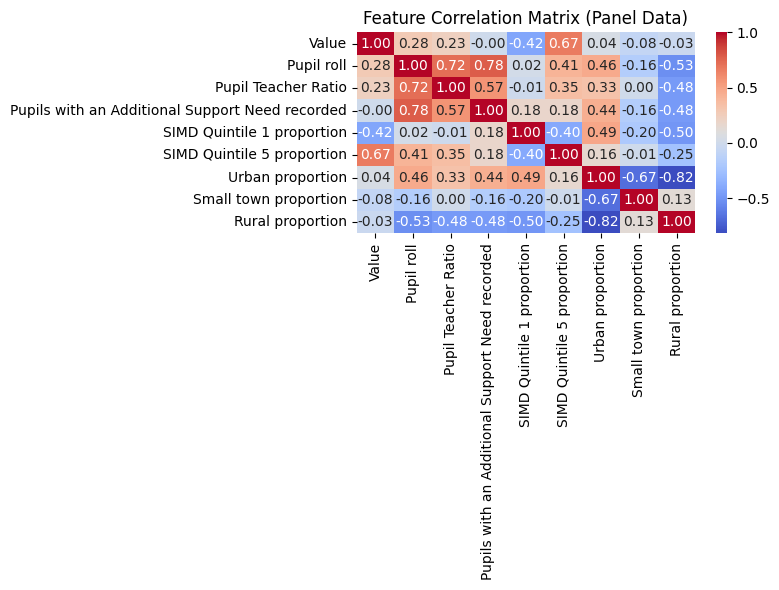

In [200]:
# Select numeric features of interest plus the target
corr_features = [
    "Value", 
    "Pupil roll", 
    "Pupil Teacher Ratio", 
    "Pupils with an Additional Support Need recorded",
    "SIMD Quintile 1 proportion",
    "SIMD Quintile 5 proportion",
    *URF
]

# Calculate Pearson correlation matrix
corr_matrix = panel_df[corr_features].corr(method="pearson")
print("Pearson Correlation Matrix:")
display(corr_matrix)

# Optional: Visualize using plotnine or seaborn
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Matrix (Panel Data)")
plt.tight_layout()
plt.show()

In [197]:
from scipy import stats

# Pivot data to get schools as rows and years as columns for paired testing
pivoted = panel_df.pivot(index="School Name", columns="Year", values="Value").dropna()

if 2024 in pivoted.columns and 2025 in pivoted.columns:
    stat, p_value = stats.wilcoxon(pivoted[2024], pivoted[2025])
    print(f"Wilcoxon signed-rank test (2024 vs 2025): Statistic = {stat:.4f}, p-value = {p_value:.4e}")

In [ ]:
# year_groups = [group["Value"].dropna() for name, group in panel_df.groupby("Year")]
# kw_stat, kw_pvalue = stats.kruskal(*year_groups)
# print(f"Kruskal-Wallis H-test across years: Stat = {kw_stat:.4f}, p-value = {kw_pvalue:.4e}")

AttributeError: 'float' object has no attribute 'dtype'

In [ ]:
# import statsmodels.api as sm
# import statsmodels.formula.api as smf

# # Clean up column names for formula syntax (remove spaces)
# regression_df = panel_df.dropna(subset=["Value", "Pupil Teacher Ratio", "Pupil roll"]).copy()
# regression_df.columns = [c.replace(" ", "_").replace("%", "pct") for c in regression_df.columns]

# # Fit a Fixed Effects model using School_Name as entity effects
# fe_model = smf.ols(
#     formula="Value ~ Pupil_Teacher_Ratio + Pupil_roll + C(Year)", 
#     data=regression_df
# ).fit()

# print(fe_model.summary())

ValueError: endog has evaluated to an array with multiple columns that has shape (1685, 81). This occurs when the variable converted to endog is non-numeric (e.g., bool or str).

---
# CFE Testing

In [207]:
la_sum = hs_sum_2025.groupby("Local Authority").agg({
    "Pupil roll": "sum",
    "Pupil Teacher Ratio": "mean",
    "SIMD Quintile 1 proportion": "mean",
    "SIMD Quintile 5 proportion": "mean",
    "Urban proportion": "mean",
    "Small town proportion": "mean",
    "Rural proportion": "mean"
}).reset_index()

print(la_sum.head())


     Local Authority  Pupil roll Pupil Teacher Ratio  \
0      Aberdeen City       11411                12.7   
1      Aberdeenshire       15889           12.382353   
2              Angus        6492               11.55   
3    Argyll and Bute        4387             10.8875   
4  City of Edinburgh       24310                12.9   

   SIMD Quintile 1 proportion  SIMD Quintile 5 proportion  Urban proportion  \
0                    0.093197                    0.345832          0.868182   
1                    0.037371                    0.380372          0.328571   
2                    0.079694                    0.181143          0.600000   
3                    0.125934                    0.037921          0.350000   
4                    0.226179                    0.329446          0.915217   

   Small town proportion  Rural proportion  
0               0.078571          0.104545  
1               0.303333          0.485294  
2               0.290000          0.237500  
3       

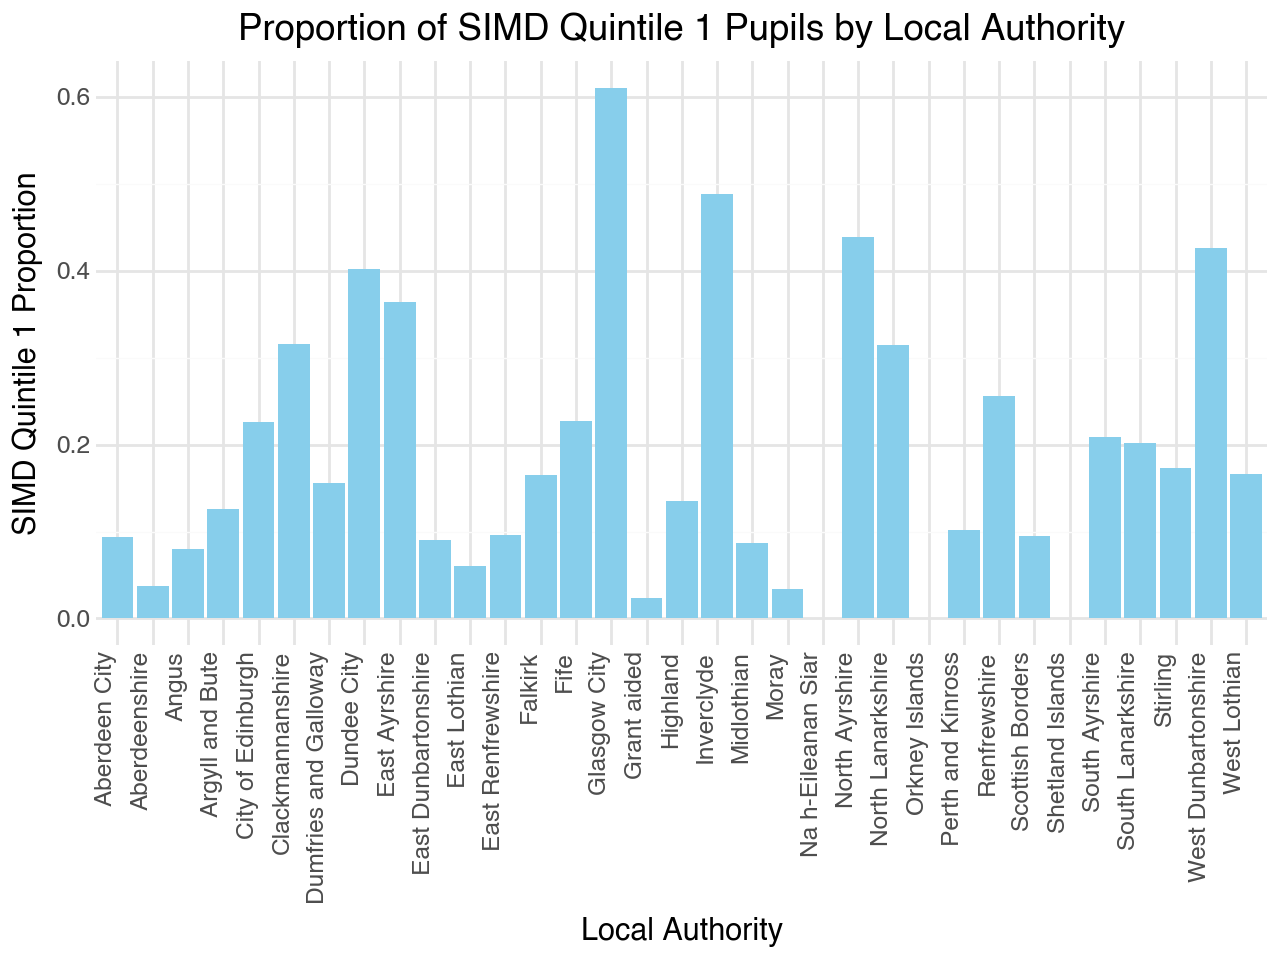

In [ ]:

(
    ggplot(la_sum, aes(x="Local Authority", y="SIMD Quintile 1 proportion"))
    + geom_bar(stat="identity", fill="skyblue")
    + theme_minimal()
    + theme(axis_text_x=element_text(rotation=90, hjust=1))
    + labs(
        title="Proportion of SIMD Quintile 1 Pupils by Local Authority",
        x="Local Authority",
        y="SIMD Quintile 1 Proportion"
    )
)

In [211]:
import pandas as pd
from plotnine import *

# Load Table 10 starting from the data rows
df_t10 = pd.read_excel('cfe_sts/cfe_2425.xlsx', sheet_name='Table_10', skiprows=4)

# Assign clear column names corresponding to Table 10 layout
df_t10.columns = [
    'Stage', 'Organiser', 'Local Authority', 
    '2016-17', '2017-18', '2018-19', '2019-20', 
    '2020-21', '2021-22', '2022-23', '2023-24', '2024-25',
    'N1', 'N2', 'N3'
]

# Keep relevant columns and filter out header description rows
years = ['2016-17', '2017-18', '2018-19', '2019-20', '2020-21', '2021-22', '2022-23', '2023-24', '2024-25']
df_t10 = df_t10[['Stage', 'Organiser', 'Local Authority'] + years].dropna(subset=['Local Authority'])
df_t10 = df_t10[df_t10['Local Authority'] != 'Local Authority [note 8]']

# Melt wide columns into long format for multi-year tracking
df_long = df_t10.melt(
    id_vars=['Stage', 'Organiser', 'Local Authority'],
    value_vars=years,
    var_name='Year',
    value_name='Percentage'
)

# Convert percentage values to numeric (suppressed values like '[w]' become NaN automatically)
df_long['Percentage'] = pd.to_numeric(df_long['Percentage'], errors='coerce')

print(df_long.head())

  Stage Organiser   Local Authority     Year  Percentage
0    P1   Reading     Aberdeen City  2016-17   75.312801
1    P1   Reading     Aberdeenshire  2016-17   78.982155
2    P1   Reading             Angus  2016-17   83.916667
3    P1   Reading     Argyll & Bute  2016-17   84.190231
4    P1   Reading  Clackmannanshire  2016-17   80.662983


In [212]:
# Filter for P1 Reading across all councils and years
p1_reading_trend = df_long[
    (df_long['Stage'] == 'P1') & 
    (df_long['Organiser'] == 'Reading')
]

# View summary statistics for the latest available year (2024-25)
latest_summary = p1_reading_trend[p1_reading_trend['Year'] == '2024-25'].describe()
print(latest_summary)

       Percentage
count   33.000000
mean    81.859071
std      3.924995
min     72.411884
25%     80.082742
50%     81.526453
75%     84.098361
max     92.464539


/Users/jack/.pyenv/versions/3.14.5/lib/python3.14/site-packages/plotnine/layer.py:374: PlotnineWarning: geom_point : Removed 4 rows containing missing values.


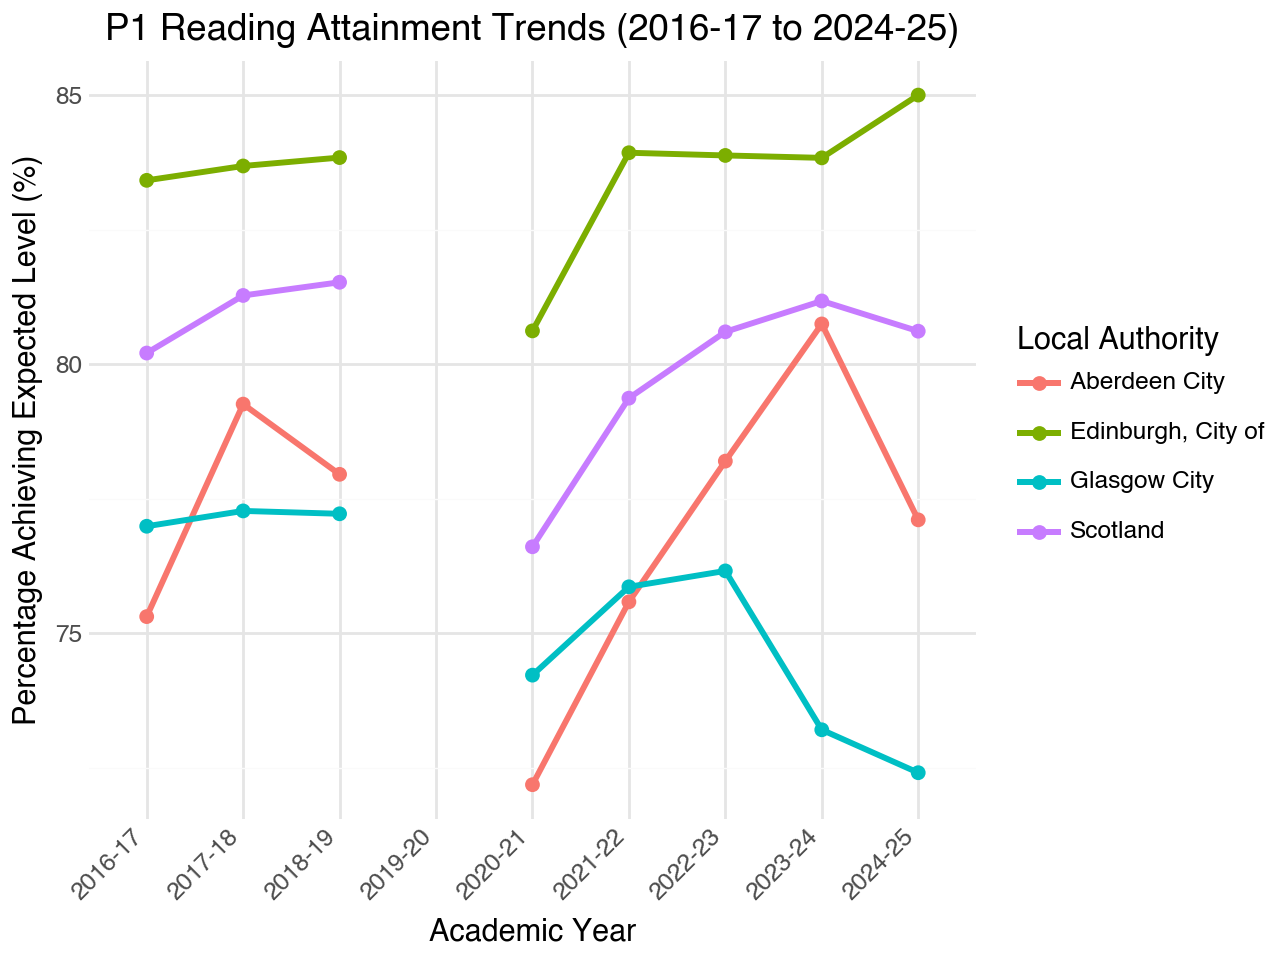

In [213]:
# Select a few councils and Scotland to plot
sample_authorities = ['Glasgow City', 'Edinburgh, City of', 'Aberdeen City', 'Scotland']
subset_trend = p1_reading_trend[p1_reading_trend['Local Authority'].isin(sample_authorities)]

# Generate multi-year trend visualization
(
    ggplot(subset_trend, aes(x='Year', y='Percentage', color='Local Authority', group='Local Authority'))
    + geom_line(size=1.2)
    + geom_point(size=2)
    + theme_minimal()
    + theme(axis_text_x=element_text(rotation=45, hjust=1))
    + labs(
        title='P1 Reading Attainment Trends (2016-17 to 2024-25)',
        x='Academic Year',
        y='Percentage Achieving Expected Level (%)',
        color='Local Authority'
    )
)

In [215]:
import pandas as pd
from plotnine import *

# Load Table 11 starting from the header row
df_t11 = pd.read_excel('cfe_sts/cfe_2425.xlsx', sheet_name='Table_11', skiprows=3)

# Assign clean column names
df_t11.columns = [
    'Year', 'Stage', 'Local Authority', 'SIMD Quintile', 
    'Reading', 'Writing', 'Listening_Talking', 'Literacy', 'Numeracy'
]

# Drop any potential header residual rows or NaNs in Local Authority
df_t11 = df_t11.dropna(subset=['Local Authority'])
df_t11 = df_t11[df_t11['Local Authority'] != 'Local Authority [note 7]']

# Convert metric columns to numeric
metric_cols = ['Reading', 'Writing', 'Listening_Talking', 'Literacy', 'Numeracy']
for col in metric_cols:
    df_t11[col] = pd.to_numeric(df_t11[col], errors='coerce')

print(df_t11.head())

      Year             Stage Local Authority  \
1  2024-25  P1 (Early Level)   Aberdeen City   
2  2024-25  P1 (Early Level)   Aberdeen City   
3  2024-25  P1 (Early Level)   Aberdeen City   
4  2024-25  P1 (Early Level)   Aberdeen City   
5  2024-25  P1 (Early Level)   Aberdeen City   

                      SIMD Quintile    Reading    Writing  Listening_Talking  \
1   SIMD Quintile 1 - most deprived  67.487685  65.024631          78.817734   
2                   SIMD Quintile 2  67.342342  65.990991          79.325843   
3                   SIMD Quintile 3  77.627119  76.949153          86.779661   
4                   SIMD Quintile 4  81.360947  79.289941          85.502959   
5  SIMD Quintile 5 - least deprived  85.348506  83.214794          91.038407   

    Literacy   Numeracy  
1  59.605911  76.354680  
2  63.288288  76.629213  
3  74.237288  83.728814  
4  76.035503  83.727811  
5  80.512091  89.473684  


In [216]:
# Filter for P1 Reading in 2024-25
p1_simd = df_t11[
    (df_t11['Stage'].str.contains('P1')) & 
    (df_t11['SIMD Quintile'].str.contains('Quintile 1|Quintile 5'))
].copy()

# Pivot to place Quintile 1 and Quintile 5 side by side for gap calculation
p1_pivot = p1_simd.pivot_table(
    index=['Local Authority', 'Stage', 'Year'],
    columns='SIMD Quintile',
    values='Reading'
).reset_index()

# Rename columns for clarity (handling varying text strings)
q1_col = [c for c in p1_pivot.columns if 'Quintile 1' in c][0]
q5_col = [c for c in p1_pivot.columns if 'Quintile 5' in c][0]

p1_pivot['Attainment_Gap'] = p1_pivot[q5_col] - p1_pivot[q1_col]

print(p1_pivot[['Local Authority', q1_col, q5_col, 'Attainment_Gap']].sort_values(by='Attainment_Gap', ascending=False).head(10))

SIMD Quintile      Local Authority  SIMD Quintile 1 - most deprived  \
243                       Highland                        33.067729   
376               Scottish Borders                        53.608247   
133            East Dunbartonshire                        59.322034   
377               Scottish Borders                        60.465116   
292                          Moray                        60.000000   
251                       Highland                        41.875000   
275                     Midlothian                        50.000000   
134            East Dunbartonshire                        60.810811   
152                   East Lothian                        53.146853   
21                   Aberdeenshire                        52.112676   

SIMD Quintile  SIMD Quintile 5 - least deprived  Attainment_Gap  
243                                   70.689655       37.621926  
376                                   90.721649       37.113402  
133                 

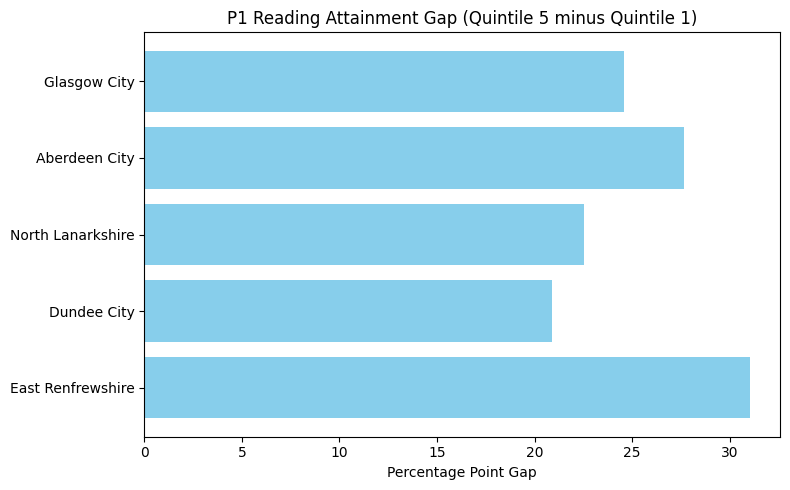

In [219]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load and clean Table 11
df_t11 = pd.read_excel('cfe_sts/cfe_2425.xlsx', sheet_name='Table_11', skiprows=3)
df_t11.columns = [
    'Year', 'Stage', 'Local Authority', 'SIMD Quintile', 
    'Reading', 'Writing', 'Listening_Talking', 'Literacy', 'Numeracy'
]
df_t11 = df_t11.dropna(subset=['Local Authority'])
df_t11 = df_t11[df_t11['Local Authority'] != 'Local Authority [note 7]']
df_t11['Reading'] = pd.to_numeric(df_t11['Reading'], errors='coerce')

# 2. Filter for P1 and Quintiles 1 & 5, then compute the gap
p1_simd = df_t11[
    (df_t11['Stage'].str.contains('P1')) & 
    (df_t11['SIMD Quintile'].str.contains('Quintile 1|Quintile 5'))
].copy()

p1_pivot = p1_simd.pivot_table(
    index=['Local Authority', 'Stage', 'Year'],
    columns='SIMD Quintile',
    values='Reading'
).reset_index()

q1_col = [c for c in p1_pivot.columns if 'Quintile 1' in c][0]
q5_col = [c for c in p1_pivot.columns if 'Quintile 5' in c][0]
p1_pivot['Attainment_Gap'] = p1_pivot[q5_col] - p1_pivot[q1_col]

# 3. Select sample local authorities and sort in pandas
sample_councils = ['Glasgow City', 'Edinburgh, City of', 'Aberdeen City', 'Dundee City', 'East Renfrewshire', 'North Lanarkshire']
subset_gap = p1_pivot[p1_pivot['Local Authority'].isin(sample_councils)].copy()
subset_gap = subset_gap.sort_values('Attainment_Gap', ascending=True)

# 4. Generate horizontal bar chart
plt.figure(figsize=(8, 5))
plt.barh(subset_gap['Local Authority'], subset_gap['Attainment_Gap'], color='skyblue')
plt.xlabel('Percentage Point Gap')
plt.title('P1 Reading Attainment Gap (Quintile 5 minus Quintile 1)')
plt.tight_layout()
plt.show()